In [2]:
def neural_network(input, weights):
    out = 0
    for i in range(len(input)):
        out += (input[i] * weights[i])
        return out

def ele_mul(scalar, vector):
    out = [0,0,0]
    
    for i in range(len(out)):
        out[i] = vector[i] * scalar
        return out
        
toes = [8.5, 9.5, 9.9, 9.0]
wlrec = [0.65, 0.8, 0.8, 0.9]
nfans = [1.2, 1.3, 0.5, 1.0]

win_or_lose_binary = [1, 1, 0, 1]
true = win_or_lose_binary[0]
alpha = 0.3
weights = [0.1, 0.2, -.1]
input = [toes[0], wlrec[0], nfans[0]]

for iter in range(3):
    pred = neural_network(input, weights)
    error = (pred - true) ** 2
    
    delta = pred - true
    weight_deltas=ele_mul(delta, input)
    
    weight_deltas[0] = 0
    print("Iteration:" + str(iter+1))
    print("Pred:" + str(pred))
    print("Error:" + str(error))
    print("Delta:" + str(delta))
    print("Weights:" + str(weights))
    print("Weight_Deltas:")
    print(str(weight_deltas))
    
    print()
    
    for i in range(len(weights)):
        weights[i] -= alpha * weight_deltas[i]

Iteration:1
Pred:0.8500000000000001
Error:0.022499999999999975
Delta:-0.1499999999999999
Weights:[0.1, 0.2, -0.1]
Weight_Deltas:
[0, 0, 0]

Iteration:2
Pred:0.8500000000000001
Error:0.022499999999999975
Delta:-0.1499999999999999
Weights:[0.1, 0.2, -0.1]
Weight_Deltas:
[0, 0, 0]

Iteration:3
Pred:0.8500000000000001
Error:0.022499999999999975
Delta:-0.1499999999999999
Weights:[0.1, 0.2, -0.1]
Weight_Deltas:
[0, 0, 0]



Iteration:1
Pred:0.8600000000000001
Error:0.01959999999999997
Delta:-0.1399999999999999
Weights:[0.1, 0.2, -0.1]
Weight_Deltas:
[0, -0.09099999999999994, -0.16799999999999987]

Iteration:2
Pred:0.9382250000000001
Error:0.003816150624999989
Delta:-0.06177499999999991
Weights:[0.1, 0.2273, -0.04960000000000005]
Weight_Deltas:
[0, -0.040153749999999946, -0.07412999999999989]

Iteration:3
Pred:0.97274178125
Error:0.000743010489422852
Delta:-0.027258218750000007
Weights:[0.1, 0.239346125, -0.02736100000000008]
Weight_Deltas:
[0, -0.017717842187500006, -0.032709862500000006]



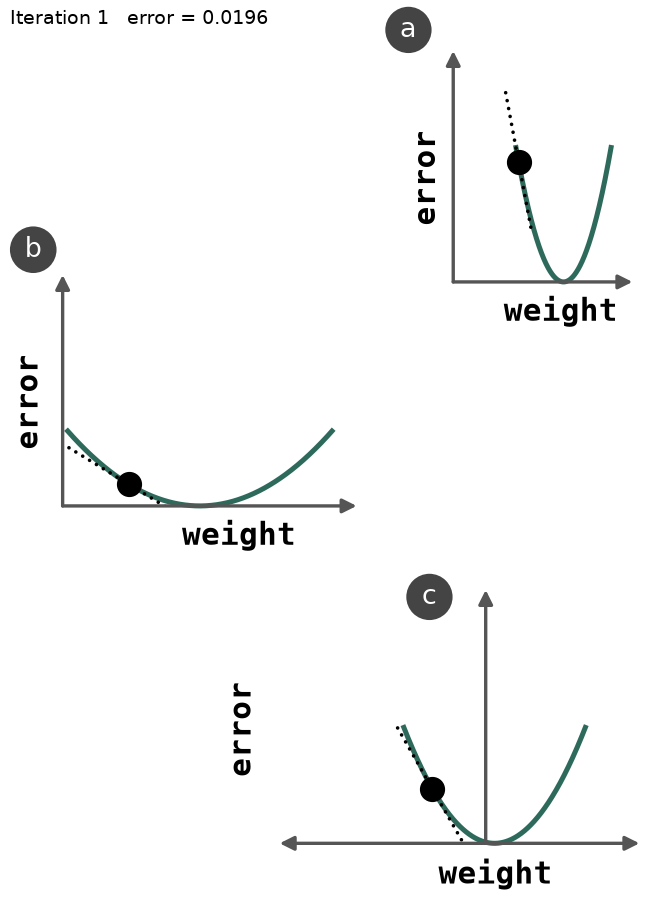

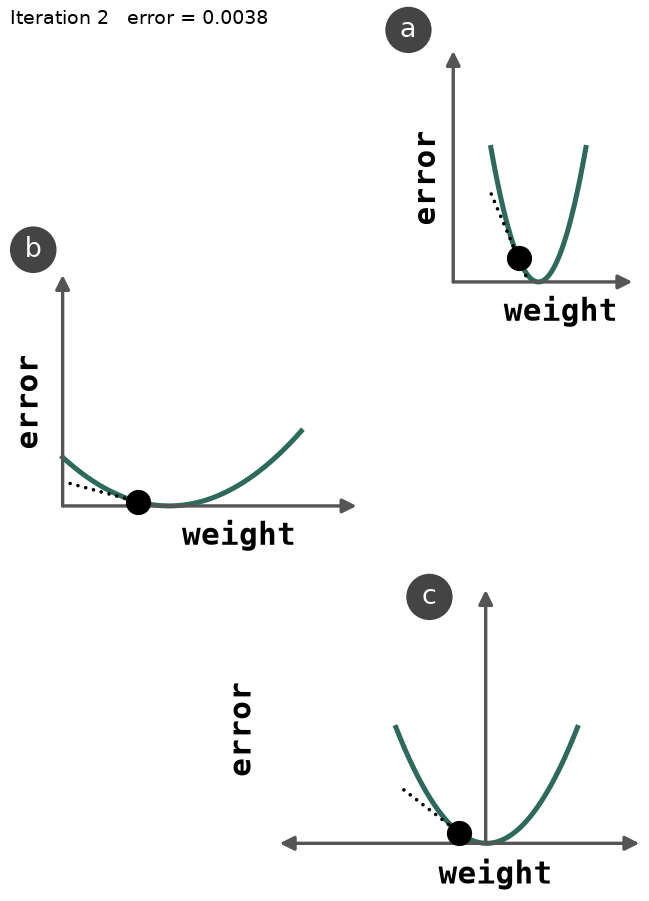

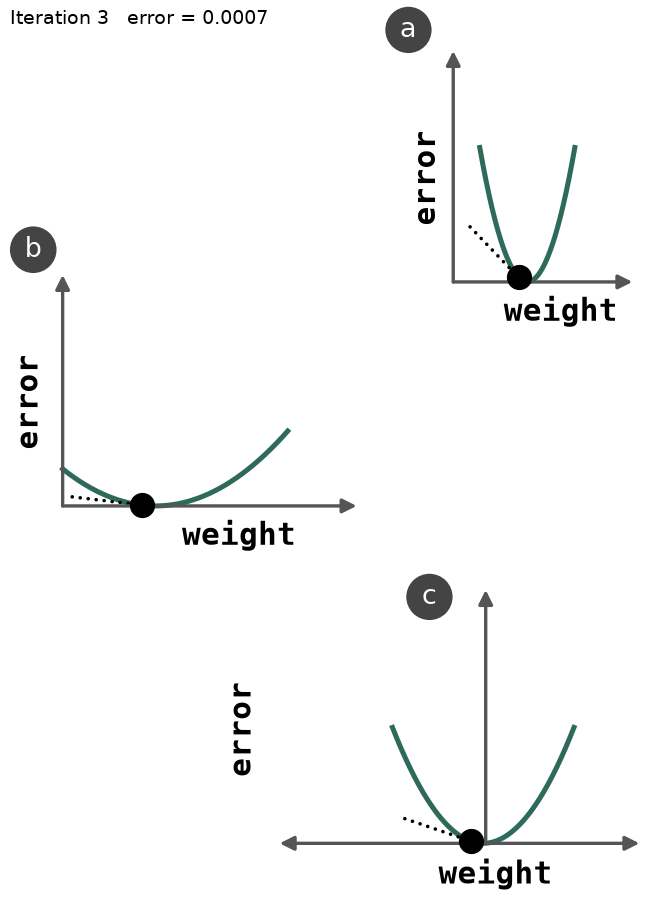

In [3]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

def neural_network(input, weights):
    out = 0
    for i in range(len(input)):
        out += (input[i] * weights[i])
    return out

def ele_mul(scalar, vector):
    out = [0,0,0]
    for i in range(len(out)):
        out[i] = vector[i] * scalar
    return out

toes = [8.5, 9.5, 9.9, 9.0]
wlrec = [0.65, 0.8, 0.8, 0.9]
nfans = [1.2, 1.3, 0.5, 1.0]

win_or_lose_binary = [1, 1, 0, 1]
true = win_or_lose_binary[0]
alpha = 0.3
weights = [0.1, 0.2, -.1]
input = [toes[0], wlrec[0], nfans[0]]

history = []

for iter in range(3):
    pred = neural_network(input, weights)
    error = (pred - true) ** 2

    delta = pred - true
    weight_deltas = ele_mul(delta, input)

    weight_deltas[0] = 0
    print("Iteration:" + str(iter+1))
    print("Pred:" + str(pred))
    print("Error:" + str(error))
    print("Delta:" + str(delta))
    print("Weights:" + str(weights))
    print("Weight_Deltas:")
    print(str(weight_deltas))
    print()

    history.append({"weights": weights.copy(), "pred": pred, "error": error, "delta": delta})

    for i in range(len(weights)):
        weights[i] -= alpha * weight_deltas[i]


GREEN, AXIS = "#2e6a5b", "#555555"

PAGE_W, PAGE_H = 520, 680
GRAPHS = [
    dict(name="a", box=(327, 40, 455, 205), xlim=(0.0761, 0.1417), ylim=(0, 0.0376), curve=0.0174, mark=(295, 25)),
    dict(name="b", box=(48, 200, 258, 365), xlim=(0.0, 0.89), ylim=(0, 0.2086), curve=0.40, mark=(27, 182)),
    dict(name="c", box=(203, 425, 460, 606), xlim=(-0.386, 0.288), ylim=(0, 0.091), curve=0.17, mark=(310, 430)),
]
TANGENT_PX = 50
DOT_PX = 17
S = 1.4
PT = 72 / 100 * S


def error_curve(i, w, snap):
    others = snap["pred"] - input[i] * snap["weights"][i]
    return (others + input[i] * w - true) ** 2


def draw_graph(fig, i, snap, g):
    x0, y0, x1, y1 = g["box"]
    ax = fig.add_axes([x0 / PAGE_W, 1 - y1 / PAGE_H, (x1 - x0) / PAGE_W, (y1 - y0) / PAGE_H])
    (xmin, xmax), (ymin, ymax) = g["xlim"], g["ylim"]
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.axis("off")

    w = snap["weights"][i]
    others = snap["pred"] - input[i] * w
    w_star = (true - others) / input[i]

    xs = np.linspace(max(w_star - g["curve"], xmin), min(w_star + g["curve"], xmax), 400)
    ax.plot(xs, error_curve(i, xs, snap), color=GREEN, linewidth=3.6 * PT, clip_on=False)

    sx = (x1 - x0) / (xmax - xmin)
    sy = (y1 - y0) / (ymax - ymin)
    slope = 2 * snap["delta"] * input[i]
    dx_px = TANGENT_PX / np.hypot(1, slope * sy / sx)
    tx = np.array([w - dx_px / sx, w + dx_px / sx])
    ax.plot(tx, snap["error"] + slope * (tx - w), color="black",
            linestyle=(0, (0.01, 2.2)), dash_capstyle="round", linewidth=2.6 * PT, zorder=3)

    ax.scatter(w, snap["error"], color="black", s=(DOT_PX * PT) ** 2, zorder=5, clip_on=False)

    y_axis_x = 0 if xmin < 0 < xmax else xmin
    arrow = dict(color=AXIS, lw=2.4 * PT, shrinkA=0, shrinkB=0, mutation_scale=15 * S)
    x_style = "<|-|>" if y_axis_x != xmin else "-|>"
    ax.annotate("", xy=(xmax, 0), xytext=(xmin, 0), arrowprops=dict(arrowstyle=x_style, **arrow), annotation_clip=False)
    ax.annotate("", xy=(y_axis_x, ymax), xytext=(y_axis_x, 0), arrowprops=dict(arrowstyle="-|>", **arrow), annotation_clip=False)

    font = dict(family="monospace", weight="bold", fontsize=16 * S)
    ax.text(-0.06, 0.45, "error", transform=ax.transAxes, rotation=90, ha="right", va="center", **font)
    ax.text(0.6, -0.06, "weight", transform=ax.transAxes, ha="center", va="top", **font)

    mx, my = g["mark"]
    fig.text(mx / PAGE_W, 1 - my / PAGE_H, g["name"], ha="center", va="center", color="white",
             fontsize=14 * S, bbox=dict(boxstyle="circle,pad=0.35", fc="#444444", ec="none"))


for r, snap in enumerate(history):
    fig = plt.figure(figsize=(PAGE_W / 100 * S, PAGE_H / 100 * S), dpi=100)
    fig.text(0.02, 0.985, f"Iteration {r+1}   error = {snap['error']:.4f}", va="top", fontsize=10 * S)
    for i, g in enumerate(GRAPHS):
        draw_graph(fig, i, snap, g)
    plt.show()


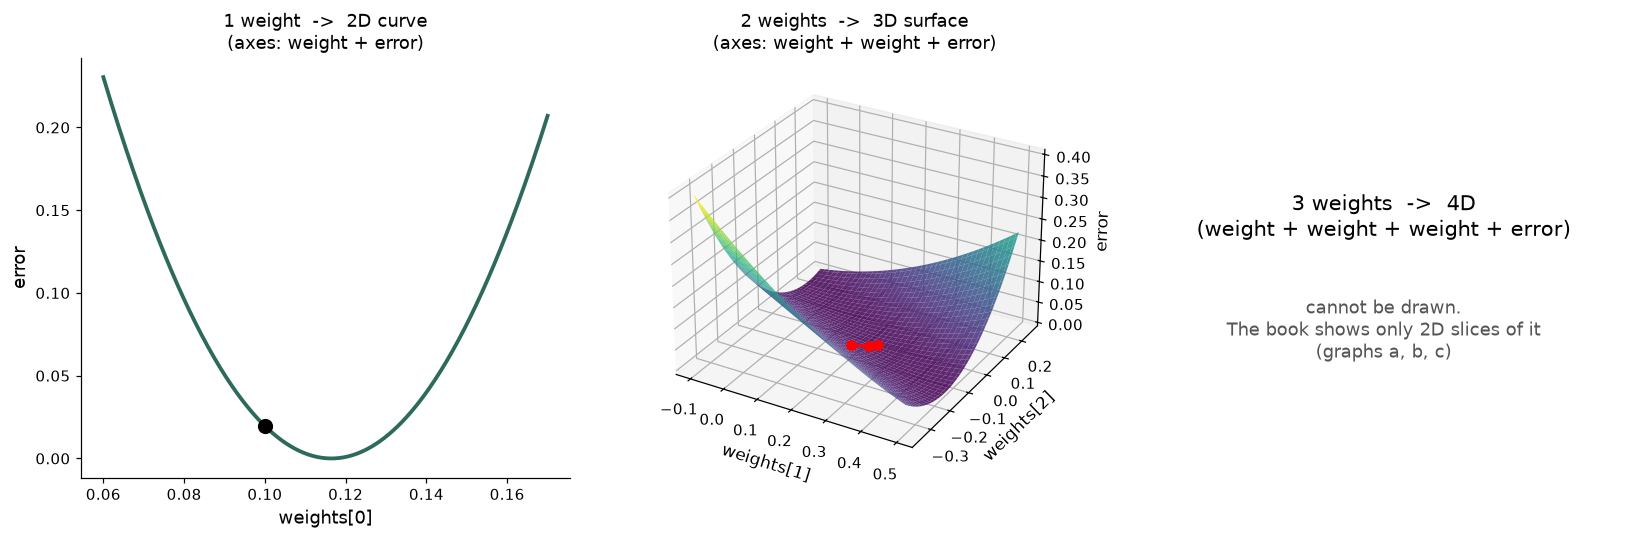

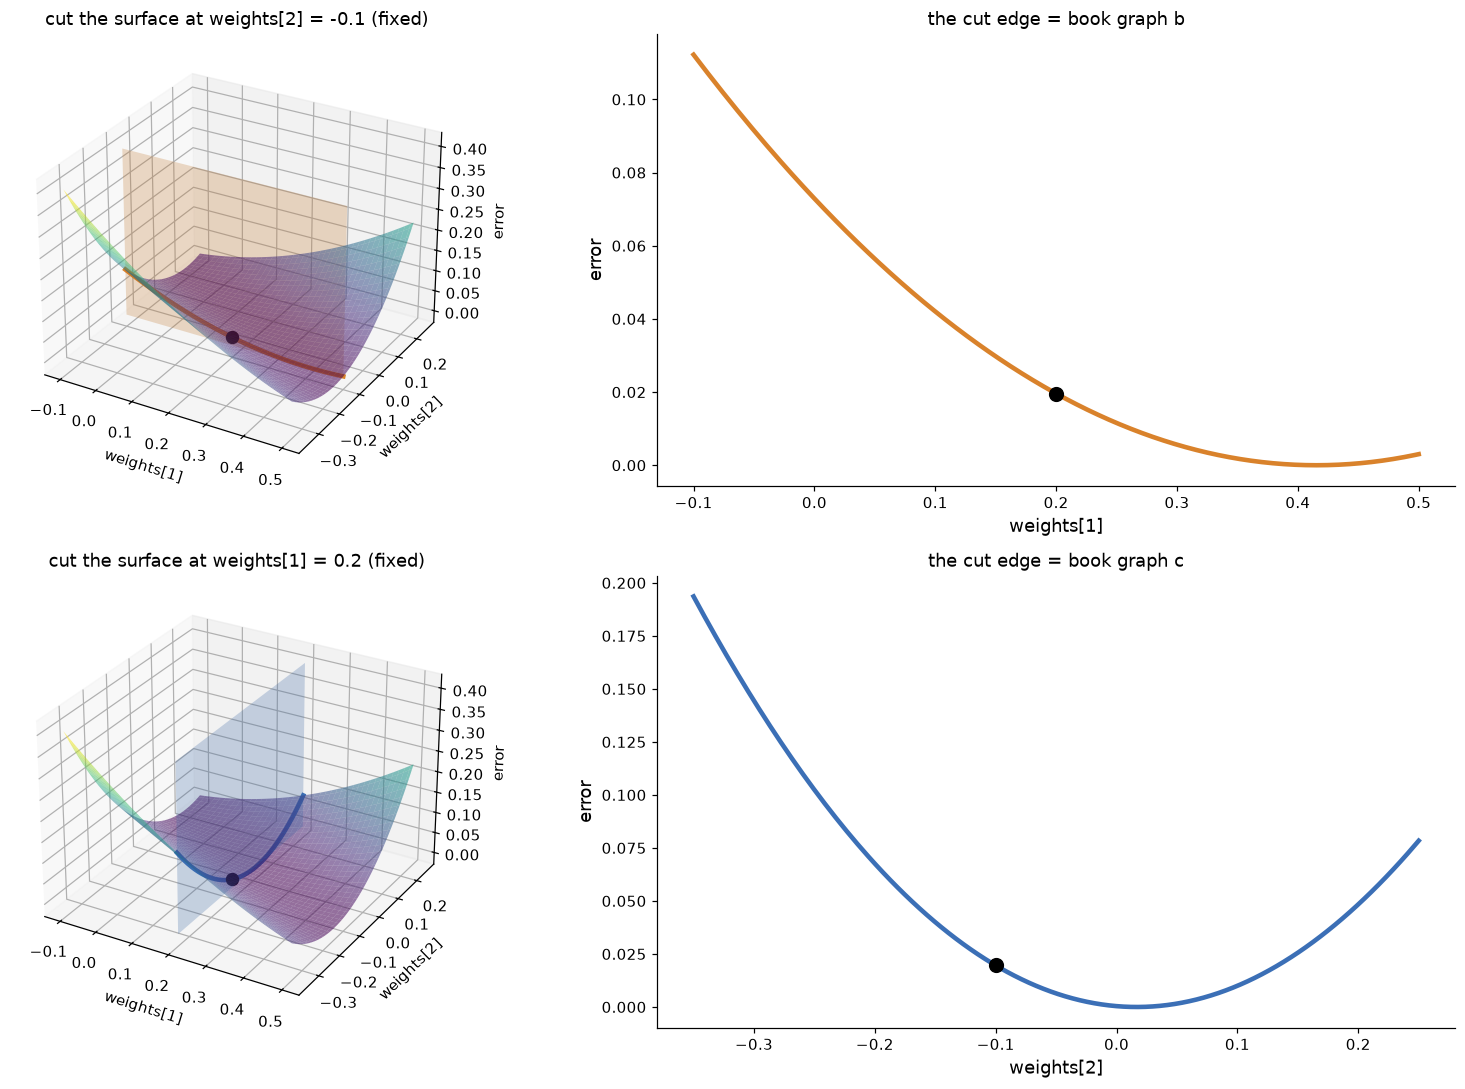

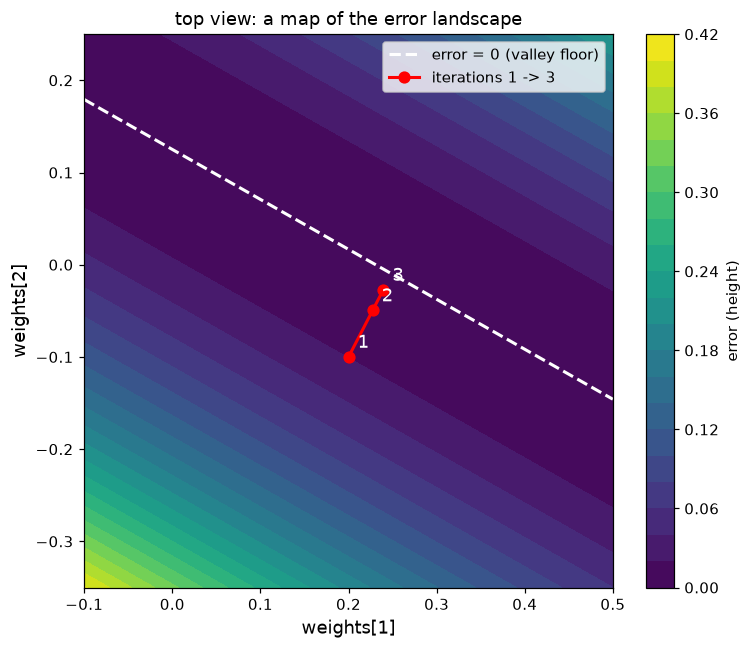

In [4]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

input = [8.5, 0.65, 1.2]
true = 1
alpha = 0.3
weights = [0.1, 0.2, -0.1]

path = []
for iter in range(3):
    pred = input[0]*weights[0] + input[1]*weights[1] + input[2]*weights[2]
    error = (pred - true) ** 2
    delta = pred - true
    path.append((weights[1], weights[2], error))
    weights[1] -= alpha * delta * input[1]
    weights[2] -= alpha * delta * input[2]
path = np.array(path)

GREEN, ORANGE, BLUE = "#2e6a5b", "#d9822b", "#3b6fb6"


def error_fn(w0, w1, w2):
    pred = input[0]*w0 + input[1]*w1 + input[2]*w2
    return (pred - true) ** 2


# ---------- Figure 1: 차원 사다리 ----------
fig = plt.figure(figsize=(15, 5), dpi=110)

ax1 = fig.add_subplot(1, 3, 1)
w = np.linspace(0.06, 0.17, 300)
e = error_fn(w, 0.2, -0.1)
ax1.plot(w, e, color=GREEN, lw=2.5)
ax1.scatter(0.1, error_fn(0.1, 0.2, -0.1), color="black", s=80, zorder=5)
ax1.set_xlabel("weights[0]", fontsize=12)
ax1.set_ylabel("error", fontsize=12)
ax1.set_title("1 weight  ->  2D curve\n(axes: weight + error)", fontsize=12)
ax1.spines[["top", "right"]].set_visible(False)

ax2 = fig.add_subplot(1, 3, 2, projection="3d")
W1, W2 = np.meshgrid(np.linspace(-0.1, 0.5, 80), np.linspace(-0.35, 0.25, 80))
E = error_fn(0.1, W1, W2)
ax2.plot_surface(W1, W2, E, cmap="viridis", alpha=0.85, linewidth=0)
ax2.plot(path[:, 0], path[:, 1], path[:, 2] + 0.003, color="red", lw=2, marker="o", ms=6, zorder=10)
ax2.set_xlabel("weights[1]", fontsize=11)
ax2.set_ylabel("weights[2]", fontsize=11)
ax2.set_zlabel("error", fontsize=11)
ax2.set_title("2 weights  ->  3D surface\n(axes: weight + weight + error)", fontsize=12)
ax2.view_init(elev=28, azim=-60)

ax3 = fig.add_subplot(1, 3, 3)
ax3.axis("off")
ax3.text(0.5, 0.62, "3 weights  ->  4D\n(weight + weight + weight + error)",
         ha="center", va="center", fontsize=14)
ax3.text(0.5, 0.35, "cannot be drawn.\nThe book shows only 2D slices of it\n(graphs a, b, c)",
         ha="center", va="center", fontsize=12, color="#555555")

plt.tight_layout()
plt.show()


# ---------- Figure 2: 지형을 자르면 그래프 b, c가 나온다 ----------
w1_now, w2_now, e_now = path[0]

fig = plt.figure(figsize=(15, 10), dpi=110)

for row, (fixed_name, color) in enumerate([("weights[2]", ORANGE), ("weights[1]", BLUE)]):
    ax3d = fig.add_subplot(2, 2, row * 2 + 1, projection="3d")
    ax3d.plot_surface(W1, W2, E, cmap="viridis", alpha=0.55, linewidth=0)

    if row == 0:
        xs = np.linspace(-0.1, 0.5, 200)
        ys = np.full_like(xs, w2_now)
        zs = error_fn(0.1, xs, ys)
        zmax = E.max()
        px, py = np.meshgrid([-0.1, 0.5], [w2_now, w2_now])
        ax3d.plot_surface(px, py, np.array([[0, 0], [zmax, zmax]]), color=color, alpha=0.25)
        slice_x, slice_label = xs, "weights[1]"
        title = f"cut the surface at weights[2] = {w2_now:.1f} (fixed)"
    else:
        ys = np.linspace(-0.35, 0.25, 200)
        xs = np.full_like(ys, w1_now)
        zs = error_fn(0.1, xs, ys)
        zmax = E.max()
        px, py = np.meshgrid([w1_now, w1_now], [-0.35, 0.25])
        ax3d.plot_surface(px, py, np.array([[0, zmax], [0, zmax]]), color=color, alpha=0.25)
        slice_x, slice_label = ys, "weights[2]"
        title = f"cut the surface at weights[1] = {w1_now:.1f} (fixed)"

    ax3d.plot(xs, ys, zs, color=color, lw=3)
    ax3d.scatter(w1_now, w2_now, e_now, color="black", s=60, depthshade=False)
    ax3d.set_xlabel("weights[1]")
    ax3d.set_ylabel("weights[2]")
    ax3d.set_zlabel("error")
    ax3d.set_title(title, fontsize=12)
    ax3d.view_init(elev=28, azim=-60)

    ax2d = fig.add_subplot(2, 2, row * 2 + 2)
    ax2d.plot(slice_x, zs, color=color, lw=3)
    ax2d.scatter(w1_now if row == 0 else w2_now, e_now, color="black", s=80, zorder=5)
    ax2d.set_xlabel(slice_label, fontsize=12)
    ax2d.set_ylabel("error", fontsize=12)
    ax2d.set_title(f"the cut edge = book graph {'b' if row == 0 else 'c'}", fontsize=12)
    ax2d.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


# ---------- Figure 3: 위에서 내려다본 지도(등고선) ----------
fig, ax = plt.subplots(figsize=(7, 6), dpi=110)
cs = ax.contourf(W1, W2, E, levels=25, cmap="viridis")
fig.colorbar(cs, label="error (height)")
b = np.linspace(-0.1, 0.5, 100)
ax.plot(b, (true - input[0]*0.1 - input[1]*b) / input[2], color="white", lw=2, ls="--", label="error = 0 (valley floor)")
ax.plot(path[:, 0], path[:, 1], color="red", lw=2, marker="o", ms=7, label="iterations 1 -> 3")
for k, (x, y, _) in enumerate(path):
    ax.annotate(f"{k+1}", (x, y), textcoords="offset points", xytext=(6, 6), color="white", fontsize=12)
ax.set_xlim(-0.1, 0.5)
ax.set_ylim(-0.35, 0.25)
ax.set_xlabel("weights[1]", fontsize=12)
ax.set_ylabel("weights[2]", fontsize=12)
ax.set_title("top view: a map of the error landscape", fontsize=12)
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()


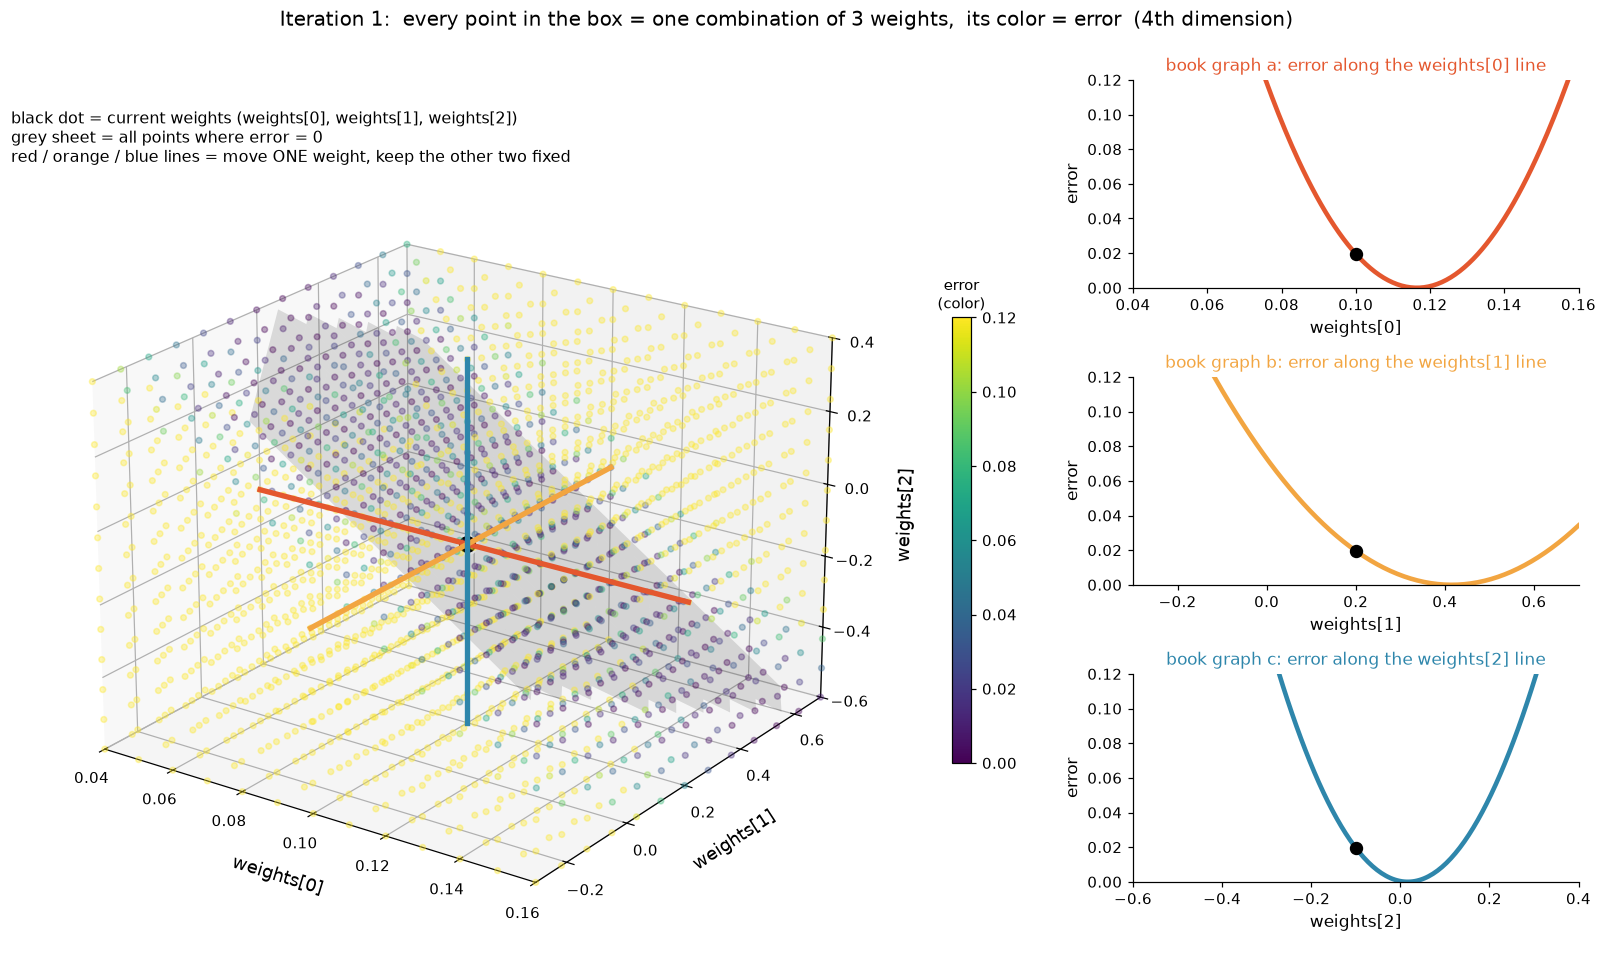

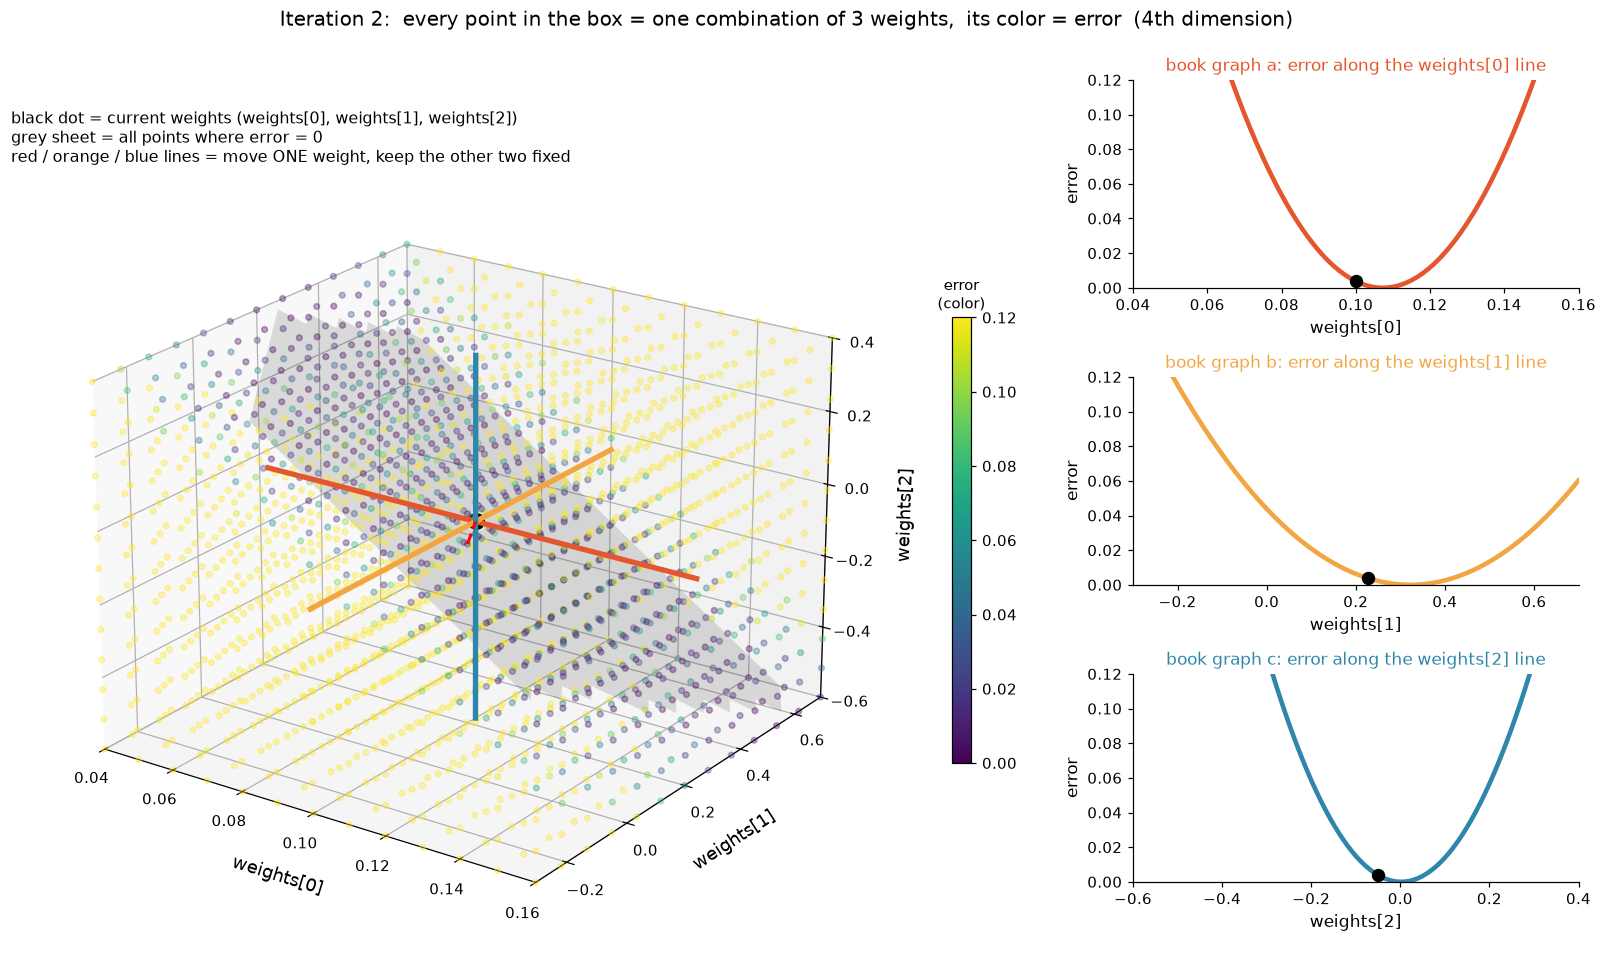

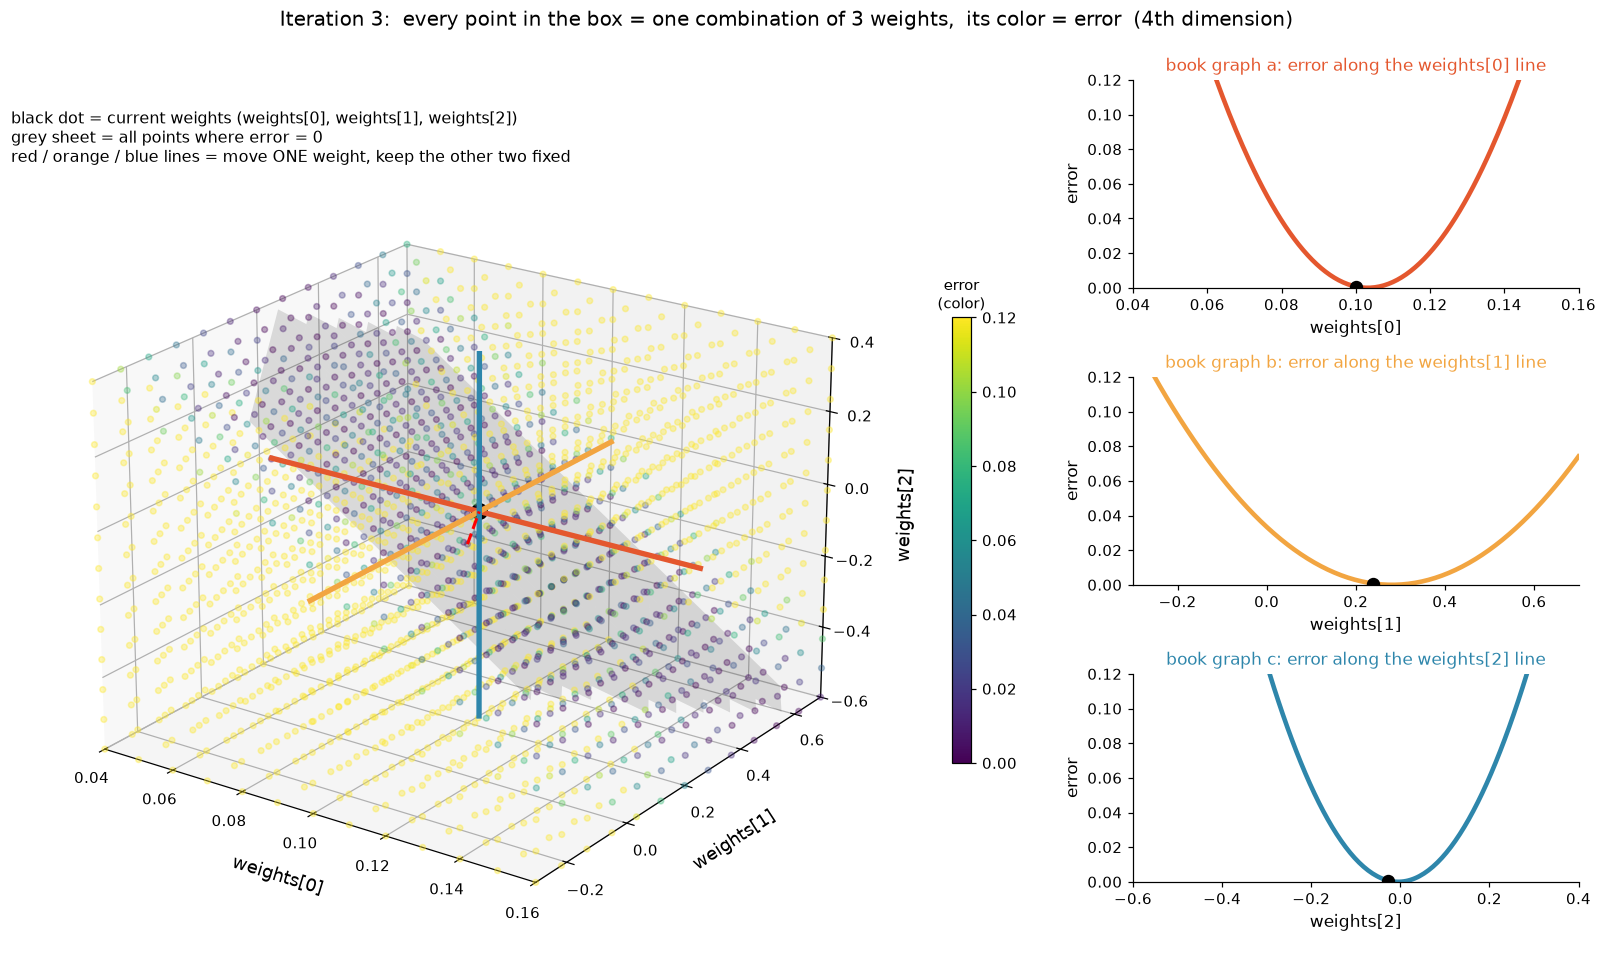

In [7]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm, colors

input = [8.5, 0.65, 1.2]
true = 1
alpha = 0.3
weights = [0.1, 0.2, -0.1]

history = []
for iter in range(3):
    pred = input[0]*weights[0] + input[1]*weights[1] + input[2]*weights[2]
    error = (pred - true) ** 2
    delta = pred - true
    history.append((weights.copy(), error))
    weight_deltas = [delta * input[0], delta * input[1], delta * input[2]]
    weight_deltas[0] = 0
    for i in range(3):
        weights[i] -= alpha * weight_deltas[i]


def error_fn(w0, w1, w2):
    pred = input[0]*w0 + input[1]*w1 + input[2]*w2
    return (pred - true) ** 2


RANGE = [(0.04, 0.16), (-0.3, 0.7), (-0.6, 0.4)]
NAMES = ["weights[0]", "weights[1]", "weights[2]"]
LINE_COLORS = ["#e4572e", "#f2a541", "#2e86ab"]
BOOK = ["a", "b", "c"]
E_MAX = 0.12
norm = colors.Normalize(0, E_MAX)
cmap = cm.viridis

g = [np.linspace(lo, hi, 13) for lo, hi in RANGE]
G0, G1, G2 = np.meshgrid(*g, indexing="ij")
GE = error_fn(G0, G1, G2)

for r, (w_now, e_now) in enumerate(history):
    fig = plt.figure(figsize=(15, 9), dpi=110)
    fig.suptitle(f"Iteration {r+1}:  every point in the box = one combination of 3 weights,  "
                 f"its color = error  (4th dimension)", fontsize=13)

    ax = fig.add_axes([0.0, 0.02, 0.6, 0.82], projection="3d")

    ax.scatter(G0.ravel(), G1.ravel(), G2.ravel(), c=np.clip(GE.ravel(), 0, E_MAX),
               cmap=cmap, norm=norm, s=14, alpha=0.35, depthshade=False)

    p1, p2 = np.meshgrid(np.linspace(*RANGE[1], 20), np.linspace(*RANGE[2], 20))
    p0 = (true - input[1]*p1 - input[2]*p2) / input[0]
    p0 = np.where((p0 >= RANGE[0][0]) & (p0 <= RANGE[0][1]), p0, np.nan)
    ax.plot_surface(p0, p1, p2, color="black", alpha=0.12, linewidth=0)

    for i in range(3):
        t = np.linspace(*RANGE[i], 120)
        pts = [np.full_like(t, w_now[k]) for k in range(3)]
        pts[i] = t
        ax.plot(*pts, color=LINE_COLORS[i], lw=3.5, zorder=10)

    path = np.array([h[0] for h in history[:r+1]])
    ax.plot(path[:, 0], path[:, 1], path[:, 2], color="red", lw=2, ls="--", zorder=11)
    ax.scatter(*w_now, color="black", edgecolor="white", linewidth=1.5, s=160, depthshade=False, zorder=12)

    ax.set_xlim(*RANGE[0]); ax.set_ylim(*RANGE[1]); ax.set_zlim(*RANGE[2])
    ax.set_xlabel(NAMES[0], fontsize=12, labelpad=10)
    ax.set_ylabel(NAMES[1], fontsize=12, labelpad=10)
    ax.set_zlabel(NAMES[2], fontsize=12, labelpad=10)
    ax.view_init(elev=22, azim=-55)

    cax = fig.add_axes([0.6, 0.22, 0.012, 0.45])
    fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax)
    cax.set_title("error\n(color)", fontsize=10)
    fig.text(0.03, 0.88, "black dot = current weights (weights[0], weights[1], weights[2])\n"
             "grey sheet = all points where error = 0\n"
             "red / orange / blue lines = move ONE weight, keep the other two fixed",
             fontsize=10.5, va="top")

    for i in range(3):
        sub = fig.add_axes([0.71, 0.70 - i * 0.30, 0.27, 0.21])
        t = np.linspace(*RANGE[i], 200)
        args = list(w_now)
        args[i] = t
        sub.plot(t, error_fn(*args), color=LINE_COLORS[i], lw=3)
        sub.scatter(w_now[i], e_now, color="black", s=60, zorder=5)
        sub.set_ylim(0, E_MAX)
        sub.set_xlim(*RANGE[i])
        sub.set_xlabel(NAMES[i], fontsize=11)
        sub.set_ylabel("error", fontsize=11)
        sub.set_title(f"book graph {BOOK[i]}: error along the {NAMES[i]} line", fontsize=11,
                      color=LINE_COLORS[i])
        sub.spines[["top", "right"]].set_visible(False)

    plt.show()
